# Modes across one comparison

Run every prepared 300-nt window from one comparison through enrichment, island identification, mode selection, and quantile-line metrics. The smallest available comparison represented in the easy-agreement examples is selected by its actual window count.

Run top to bottom on TSCC using the same environment as the existing notebooks. Review the paths below first. Required packages: NumPy, pandas, SciPy, Matplotlib, scikit-learn, and IPython. Plotly enables rotatable 3D plots with hover labels; tqdm enables a progress bar. Both have fallbacks.

The existing notebooks, preparation script, and `utils.py` are read without modification. The island and mode-selection rules, including their current limitations, are reused as they stand. No real TSCC results are embedded in this notebook.

In [24]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import traceback
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = None

try:
    import plotly.express as px
    import plotly.io as pio
    pio.renderers.default = "notebook"
except ImportError:
    px = None

## Settings

The eligible pairs come from the **easy-agreement example windows**, although the comparison table labels their comparisons `similar`. All windows of the selected comparison are analyzed, regardless of whether they appeared in the example zoo. Other comparisons are inspected only for their array dimensions.

Leave `COMPARISON_FILE = None` to choose the smaller available eligible dataset. Set an exact filename to override that selection. The default run processes every window.

In [25]:
INPUT_DIR = Path("/tscc/lustre/ddn/scratch/kflanagan/plip_plop_results/processed_inputs")
COMPARISON_TABLE = Path("/tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance/select_comparisons/encode_initial_30_comparisons.tsv")
UTILS_PATH = Path("/tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance/utils.py")
OUTPUT_ROOT = Path("mode_analysis_results")

EASY_AGREEMENT_PAIRS = {("PUM1", "PUM2"), ("FUS", "TAF15")}
COMPARISON_FILE = None

SMOOTHING_SIGMA = 2
ABUNDANCE_P = 2

ISLAND_PARAMETERS = dict(
    seed_threshold_fraction=0.4, growth_threshold_fraction=0.2,
    max_weak_distance=5, gap_tolerance=2, shape_balance_power=1.05,
    ridge_fraction=0.6,
    split_prominence_fraction=0.15, split_min_peak_fraction=0.5,
    split_min_peak_distance=8, split_min_seed_area=5,
    displacement_fold_threshold=2.0, mode_score_fraction=0.33
)

QUANTILE_PARAMETERS = dict(n_points=128, signal_influence=1.0, signal_power=1.0, smoothing_sigma=0.0)
ANGLE_QUANTILES = (0.20, 0.80)

PILOT_WINDOWS = 20
N_WORKERS = 8
CHECKPOINT_WINDOWS = 100
CHECKPOINT_SECONDS = 30
STOP_ON_ERROR = True

DBSCAN_EPS = 0.65
DBSCAN_MIN_SAMPLES = 10

## Metric definitions

Each retained mode produces one table row.

| Scatter axis | Definition |
| --- | --- |
| `angle_deg` | Quantile-line angle **minus the mode bounding-box angle**, in degrees (`angle_offset_deg` in the prototype). Zero means the signal follows the box diagonal. |
| `displacement_nt` | Signed perpendicular distance of the quantile median from the mode bounding-box diagonal (`median_displacement_nt`). Positive points toward larger A; negative toward larger B. |
| `total_shape_adjusted_signal` | The sum of each member's interval-constrained signal multiplied by `(min(A_width, B_width) / max(A_width, B_width)) ** shape_balance_power`. Widths are inclusive region bounding-box widths. No best-lag search or lag-based member pruning is used. |

The table also retains the absolute line angle, raw median `B − A` lag, allowed lag interval, unpenalized `mode_total_support`, scoring method, and genomic coordinates. Scoring and quantile fitting use the same region masks. **Box-relative displacement is not the genomic shift between A and B.** Signals are oriented 5′ to 3′, including minus-strand windows.

The scatter displays `log1p(total_shape_adjusted_signal)` so a few large scores do not hide the other modes. Raw scores remain in the table.

In [26]:
if not UTILS_PATH.is_file():
    raise FileNotFoundError(f"Set UTILS_PATH to the current utils.py: {UTILS_PATH}")

spec = importlib.util.spec_from_file_location("mode_analysis_utils", UTILS_PATH)
analysis_utils = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis_utils)
if getattr(analysis_utils, "MODE_SCORING_METHOD", None) != "interval_region":
    raise RuntimeError("Use the updated interval-scoring utils.py and restart the kernel.")

# Check the interfaces used by this notebook.
probe = np.ones((3, 3), dtype=np.float32)
positions, profile = analysis_utils.island_axis_profile(probe, probe > 0, "A")
if analysis_utils.correspondence_matrix(np.ones((1, 1, 300)), np.ones((1, 1, 300))).shape != (1, 300, 300):
    raise ValueError("Use the current correspondence_matrix without context slicing.")

utils_sha256 = hashlib.sha256(UTILS_PATH.read_bytes()).hexdigest()
print(f"Using {UTILS_PATH}\nSHA-256: {utils_sha256}")

# Load the batch worker from the same folder as utils.py.
runner_dir = UTILS_PATH.resolve().parent
if not (runner_dir / "pipeline_runner.py").is_file():
    raise FileNotFoundError("Copy pipeline_runner.py and mode_line_metrics.py beside utils.py.")
sys.path.insert(0, str(runner_dir))
import pipeline_runner
if Path(pipeline_runner.__file__).resolve() != runner_dir / "pipeline_runner.py":
    raise RuntimeError("A different pipeline_runner is loaded. Restart the kernel.")


Using /tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance/utils.py
SHA-256: ec28c5f15689142d71891427da734963427c401c321d0a5855816d43990f4e7f


In [27]:
def npz_array_shape(path, key):
    """Read an array header without decompressing its signal values."""
    with zipfile.ZipFile(path) as archive, archive.open(f"{key}.npy") as handle:
        version = np.lib.format.read_magic(handle)
        if version == (1, 0):
            shape, _, _ = np.lib.format.read_array_header_1_0(handle)
        elif version == (2, 0):
            shape, _, _ = np.lib.format.read_array_header_2_0(handle)
        else:
            raise ValueError(f"Unsupported NPY header version {version}: {path}")
    return shape


def comparison_candidates(table_path, input_dir):
    table = pd.read_csv(table_path, sep="\t")
    rows = []
    for comparison_id, row in table.iterrows():
        pair = (row["experiment_A"].split("_")[0], row["experiment_B"].split("_")[0])
        if pair not in EASY_AGREEMENT_PAIRS:
            continue
        path = input_dir / f'{row["experiment_A"]}_{row["experiment_B"]}.npz'
        candidate = dict(comparison_id=int(comparison_id), category=row["category"],
                         experiment_A=row["experiment_A"], experiment_B=row["experiment_B"],
                         path=str(path), n_windows=None, positions=None, status="missing")
        if path.is_file():
            try:
                shape = npz_array_shape(path, "ip_signals_A")
                if len(shape) != 3:
                    raise ValueError(f"Expected a 3D signal array; found {shape}")
                candidate.update(n_windows=shape[0], positions=shape[2], size_mb=path.stat().st_size / 1e6,
                                 status="ready" if shape[2] == 300 and shape[0] > 0 else "wrong_width_or_empty")
            except (ValueError, KeyError, OSError, zipfile.BadZipFile) as exc:
                candidate.update(status="unreadable", error=str(exc))
        rows.append(candidate)
    return pd.DataFrame(rows)

In [28]:
phase_timings = {}
started = perf_counter()
candidates = comparison_candidates(COMPARISON_TABLE, INPUT_DIR)
phase_timings["candidate_scan_seconds"] = perf_counter() - started
display(candidates)

if candidates.empty:
    raise ValueError("No easy-agreement pair was found in the comparison table.")

available = candidates[candidates["status"] == "ready"].copy()
if COMPARISON_FILE is not None:
    available = available[available["path"].map(lambda path: Path(path).name == Path(COMPARISON_FILE).name)]
if available.empty:
    raise ValueError("No eligible 300-nt archive is available. Check the candidate table and regenerate any old 600-nt inputs.")

selected = available.sort_values(["n_windows", "path"]).iloc[0]
INPUT_PATH = Path(selected["path"])
comparison_key = f'{selected["experiment_A"]}__{selected["experiment_B"]}'

print(f"Selected: {comparison_key}")
print(f'Windows: {int(selected["n_windows"]):,}; positions per window: 300')
print("Selection uses window count, not compressed file size.")

,comparison_id,category,experiment_A,experiment_B,path,n_windows,positions,status,size_mb
0,0,similar,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,/tscc/lustre/ddn/scratch/kflanagan/plip_plop_r...,17981,300,ready,7.545512
1,1,similar,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,/tscc/lustre/ddn/scratch/kflanagan/plip_plop_r...,12955,300,ready,4.686861


Selected: PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ
Windows: 12,955; positions per window: 300
Selection uses window count, not compressed file size.


## Load one archive

Signals remain as raw replicate arrays in memory. RPM conversion and enrichment are calculated one window at a time. The shared abundance reference uses all 300 positions of both IP tracks. Smoothing is applied to the calculated enrichment, before replicate averaging, as in the current utilities.

Old 600-position archives are rejected explicitly. No context cropping is performed.

In [29]:
def load_comparison(path, selected):
    arrays, library_sizes = {}, {}
    with np.load(path, allow_pickle=False) as archive:
        n_windows = int(selected["n_windows"])
        for group in ("ip_A", "in_A", "ip_B", "in_B"):
            signal_key = group.replace("_", "_signals_", 1)
            shape = npz_array_shape(path, signal_key)
            if len(shape) != 3 or shape[0] != n_windows or shape[2] != 300 or shape[1] < 1:
                raise ValueError(f"{signal_key} must have shape (windows, replicates, 300); found {shape}")
            arrays[group] = np.asarray(archive[signal_key], dtype=np.float32)
            sizes = np.asarray(archive[f"{group}_library_sizes"], dtype=float)
            if sizes.shape != (shape[1],) or not np.all(np.isfinite(sizes) & (sizes > 0)):
                raise ValueError(f"Invalid library sizes for {group}: {sizes}")
            library_sizes[group] = sizes

        if arrays["in_A"].shape[1] != 1 or arrays["in_B"].shape[1] != 1:
            raise ValueError("The current enrichment workflow expects one IN replicate per experiment.")

        metadata = pd.DataFrame({key: archive[key] for key in ("chrom", "start", "end", "strand", "region_id", "block_number")})

    if len(metadata) != n_windows or not (metadata["end"] - metadata["start"]).eq(300).all():
        raise ValueError("Coordinate metadata must describe the same 300-nt windows as the signal arrays.")
    metadata["chrom"] = metadata["chrom"].astype(str)
    metadata["strand"] = metadata["strand"].astype(str)
    if not metadata["strand"].isin(["+", "-"]).all():
        raise ValueError("Unexpected strand in the input metadata.")
    metadata.insert(0, "window_idx", np.arange(n_windows))
    metadata.insert(0, "comparison_id", int(selected["comparison_id"]))
    metadata["comparison_key"] = comparison_key
    metadata["experiment_A"] = selected["experiment_A"]
    metadata["experiment_B"] = selected["experiment_B"]
    metadata["category"] = selected["category"]
    metadata["window_key"] = [f"{comparison_key}:w{index:07d}" for index in range(n_windows)]
    return arrays, library_sizes, metadata


started = perf_counter()
raw_arrays, library_sizes, window_metadata = load_comparison(INPUT_PATH, selected)
pseudocounts = {group: analysis_utils.calculate_rpm_pseudocount(sizes) for group, sizes in library_sizes.items()}
phase_timings["load_seconds"] = perf_counter() - started

print(f"Loaded {len(window_metadata):,} windows in {phase_timings['load_seconds']:.2f} s")
print(f"Raw arrays: {sum(array.nbytes for array in raw_arrays.values()) / 1e9:.3f} GB")
display(window_metadata.head())

Loaded 12,955 windows in 0.21 s
Raw arrays: 0.093 GB


,comparison_id,window_idx,chrom,start,end,strand,region_id,block_number,comparison_key,experiment_A,experiment_B,category,window_key
0,1,0,chr1,630973,631273,+,0,0,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,similar,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...
1,1,1,chr1,631162,631462,+,0,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,similar,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...
2,1,2,chr1,631648,631948,+,1,0,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,similar,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...
3,1,3,chr1,631837,632137,+,1,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,similar,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...
4,1,4,chr1,632226,632526,+,2,0,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,PUM2_K562_ENCSR661ICQ,similar,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...


## Quantile-line helpers

These calculations follow the correspondence-line prototype: pool the retained interval-constrained member masks, construct marginal quantiles, project unsupported points into the mask, and measure the 20%–80% direction through the median. Only the plotting work (clipping and drawing lines) is omitted during the batch run.

The metric calculations are kept local to this notebook. The helper receives its matrix explicitly.

In [30]:
def surviving_mode_regions(data):
    """Pool the selected member masks for each retained mode."""
    matrix = data["matrix"]
    modes = []
    for source_mode in data["modes"]:
        member_masks = {}
        for island_id in source_mode["islands"]:
            mask = np.asarray(source_mode["constrained_regions"][island_id], dtype=bool)
            if mask.shape != matrix.shape or not mask.any():
                raise ValueError(f"Invalid mask for island {island_id}.")
            member_masks[int(island_id)] = mask
        if not member_masks:
            raise ValueError(f'Mode {source_mode["mode_id"]} has no supported pixels.')
        mode_mask = np.logical_or.reduce(list(member_masks.values()))
        rows, columns = np.where(mode_mask)
        modes.append(dict(mode_id=int(source_mode["mode_id"]), island_ids=tuple(member_masks),
                          mask=mode_mask, x_min=int(columns.min()), x_max=int(columns.max()),
                          y_min=int(rows.min()), y_max=int(rows.max()), source=source_mode))
    return modes


def mode_crop(array, mode):
    return array[mode["y_min"]:mode["y_max"] + 1, mode["x_min"]:mode["x_max"] + 1]


def weighted_quantile_positions(weights, quantiles):
    """Convert cumulative mass to fractional positions."""
    weights = np.clip(np.asarray(weights, dtype=float), 0, None)
    if weights.sum() == 0:
        weights = np.ones_like(weights)
    cumulative = np.r_[0.0, np.cumsum(weights) / weights.sum()]
    positions = np.linspace(0, len(weights) - 1, len(weights) + 1)
    return np.interp(quantiles, cumulative, positions)


def smooth_marginal(weights, sigma):
    if sigma <= 0:
        return weights
    radius = max(1, int(np.ceil(4 * sigma)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
    kernel /= kernel.sum()
    return np.convolve(np.pad(weights, radius, mode="edge"), kernel, mode="valid")


def prepare_marginal(weights, signal_influence, smoothing_sigma, support):
    """Blend the observed marginal with uniform supported mass."""
    support = np.asarray(support, dtype=bool)
    weights = smooth_marginal(np.asarray(weights, dtype=float), smoothing_sigma)
    weights = np.where(support, weights, 0)
    uniform = support / support.sum()
    observed = uniform if weights.sum() == 0 else weights / weights.sum()
    return signal_influence * observed + (1 - signal_influence) * uniform


def project_points_to_mask(x, y, mask):
    """Move unsupported points to their nearest valid pixel."""
    valid_rows, valid_columns = np.where(mask)
    if len(valid_rows) == 0:
        raise ValueError("Cannot project onto an empty mode mask.")
    projected_x = np.asarray(x, dtype=float).copy()
    projected_y = np.asarray(y, dtype=float).copy()
    rounded_x = np.rint(projected_x).astype(int)
    rounded_y = np.rint(projected_y).astype(int)
    in_bounds = ((rounded_x >= 0) & (rounded_x < mask.shape[1])
                 & (rounded_y >= 0) & (rounded_y < mask.shape[0]))
    valid = np.zeros(len(projected_x), dtype=bool)
    valid[in_bounds] = mask[rounded_y[in_bounds], rounded_x[in_bounds]]
    for index in np.where(~valid)[0]:
        distances = (valid_columns - projected_x[index]) ** 2 + (valid_rows - projected_y[index]) ** 2
        nearest = int(np.argmin(distances))
        projected_x[index], projected_y[index] = valid_columns[nearest], valid_rows[nearest]
    return projected_x, projected_y


def quantile_matching_line(matrix, mode, n_points=128, signal_influence=1.0, signal_power=1.0, smoothing_sigma=0.0):
    if not 0 <= signal_influence <= 1 or signal_power <= 0 or n_points < 3:
        raise ValueError("Check signal_influence, signal_power, and n_points.")
    crop = mode_crop(matrix, mode)
    mask_crop = mode_crop(mode["mask"], mode)
    positive_crop = np.where(mask_crop, np.clip(crop, 0, None), 0)
    peak = positive_crop.max()
    weighted_crop = (positive_crop / peak) ** signal_power if peak > 0 else positive_crop
    b_marginal = prepare_marginal(weighted_crop.sum(axis=0), signal_influence, smoothing_sigma, mask_crop.any(axis=0))
    a_marginal = prepare_marginal(weighted_crop.sum(axis=1), signal_influence, smoothing_sigma, mask_crop.any(axis=1))
    quantiles = np.linspace(0, 1, n_points)
    x = weighted_quantile_positions(b_marginal, quantiles) + mode["x_min"]
    y = weighted_quantile_positions(a_marginal, quantiles) + mode["y_min"]
    return project_points_to_mask(x, y, mode["mask"])


def quantile_angle_metrics(quantile_x, quantile_y, mode, lower_quantile=0.20, upper_quantile=0.80):
    """Measure the prototype's angle and median displacement."""
    if not 0 < lower_quantile < 0.5 < upper_quantile < 1:
        raise ValueError("Use lower < 0.5 < upper, strictly between 0 and 1.")
    quantile_grid = np.linspace(0, 1, len(quantile_x))
    requested = np.array([lower_quantile, 0.5, upper_quantile])
    landmark_b, landmark_a = project_points_to_mask(
        np.interp(requested, quantile_grid, quantile_x),
        np.interp(requested, quantile_grid, quantile_y), mode["mask"]
    )
    b_low, b_median, b_high = landmark_b
    a_low, a_median, a_high = landmark_a
    delta_b, delta_a = b_high - b_low, a_high - a_low
    box_delta_b = mode["x_max"] - mode["x_min"]
    box_delta_a = mode["y_max"] - mode["y_min"]
    if np.hypot(delta_b, delta_a) == 0 or box_delta_b == 0 or box_delta_a == 0:
        return None

    signal_slope = delta_a / delta_b if delta_b != 0 else np.inf
    box_slope = box_delta_a / box_delta_b
    signal_angle = np.degrees(np.arctan2(delta_a, delta_b))
    box_angle = np.degrees(np.arctan2(box_delta_a, box_delta_b))
    median_b_offset = b_median - mode["x_min"]
    median_a_offset = a_median - mode["y_min"]
    displacement_nt = (box_delta_b * median_a_offset - box_delta_a * median_b_offset) / np.hypot(box_delta_b, box_delta_a)
    displacement_normalized = (median_a_offset / box_delta_a - median_b_offset / box_delta_b) / np.sqrt(2)
    return dict(signal_angle_deg=float(signal_angle), box_angle_deg=float(box_angle),
                angle_offset_deg=float(signal_angle - box_angle),
                signal_slope=float(signal_slope), box_slope=float(box_slope),
                relative_slope=float(signal_slope / box_slope),
                median_b=float(b_median), median_a=float(a_median),
                median_lag_b_minus_a=float(b_median - a_median),
                median_displacement_nt=float(displacement_nt),
                median_displacement_normalized=float(displacement_normalized))

## Batch analysis and checkpoints

The first 20 completed windows provide an initial runtime estimate; all remaining windows then run automatically. Window complexity can vary substantially, so the estimate is approximate.

The progress bar reports elapsed time, rate, and ETA. Without tqdm, progress prints at checkpoints. Tables are checkpointed every 100 completed windows or 30 seconds, whichever comes first, and again on completion or interruption. A new timestamped output directory is created each time the batch cell is run.

Only scalar results and the averaged 300-position signals are retained. Full matrices, candidate masks, and figures are discarded after each window. The signal archive plus `window_key` and `mode_key` retain the connection needed for future heatmap inspection.

By default, an unexpected error saves the partial run and stops with its traceback. Set `STOP_ON_ERROR = False` to log errors and continue. Degenerate line fits are expected edge cases: their modes remain in the table with missing angle/displacement and are excluded from clustering.

Set `N_WORKERS` to 1–8. Windows run independently in worker processes, capped by the CPU allocation. The batch still processes every window and continues to the scatter and clustering cells. Worker completion order does not change the saved row order.


In [31]:
METRIC_COLUMNS = ["signal_angle_deg", "box_angle_deg", "angle_offset_deg", "signal_slope",
                  "box_slope", "relative_slope", "median_b", "median_a", "median_lag_b_minus_a",
                  "median_displacement_nt", "median_displacement_normalized"]
MODE_EXTRA_COLUMNS = ["mode_id", "mode_key", "island_ids", "n_islands", "mode_pixels",
                      "lag_min", "lag_max", "zero_lag", "mode_scoring_method",
                      "total_shape_adjusted_signal", "mode_total_support",
                      "angle_deg", "displacement_nt", "metric_status"] + METRIC_COLUMNS
TIMING_COLUMNS = ["status", "n_modes", "n_fitted_modes", "n_islands", "n_provisional_modes",
                  "evaluated_lags", "central_gate", "central_gate_reason", "enrichment_seconds",
                  "islands_seconds", "line_metrics_seconds", "total_seconds", "error"]

def enrich_window(index):
    rpm = {}
    for group, array in raw_arrays.items():
        coverage = array[index]
        if not np.isfinite(coverage).all() or (coverage < 0).any():
            raise ValueError(f"Invalid raw coverage in {group}, window {index}.")
        rpm[group] = coverage * (1e6 / library_sizes[group][:, None])

    mean_ab = (rpm["ip_A"].mean() + rpm["ip_B"].mean()) / 2
    signals = []
    for side in ("A", "B"):
        scores = analysis_utils.abundance_weighted_enrichment(
            rpm[f"ip_{side}"], rpm[f"in_{side}"][0],
            pseudocounts[f"ip_{side}"], pseudocounts[f"in_{side}"], mean_ab,
            p=ABUNDANCE_P, smoothing_sigma=SMOOTHING_SIGMA
        )
        signal = scores.astype(np.float32).mean(axis=0)
        if not np.isfinite(signal).all():
            raise ValueError(f"Nonfinite enrichment in {side}, window {index}.")
        signals.append(signal)
    return signals


def mode_metric_rows(result, metadata_row):
    rows = []
    for mode in surviving_mode_regions(result):
        source = mode["source"]
        quantile_x, quantile_y = quantile_matching_line(result["matrix"], mode, **QUANTILE_PARAMETERS)
        metrics = quantile_angle_metrics(quantile_x, quantile_y, mode, *ANGLE_QUANTILES)
        row = {**metadata_row, "mode_id": mode["mode_id"],
               "mode_key": f'{metadata_row["window_key"]}:m{mode["mode_id"]}',
               "island_ids": ",".join(map(str, mode["island_ids"])),
               "n_islands": len(mode["island_ids"]), "mode_pixels": int(mode["mask"].sum()),
               "lag_min": float(source["lag_min"]),
               "lag_max": float(source["lag_max"]), "zero_lag": bool(source["zero_lag"]),
               "total_shape_adjusted_signal": float(source["selection_score"]),
               "mode_scoring_method": source.get("scoring_method", "best_lag"),
               "mode_total_support": float(source["total_support"] if source.get("scoring_method") == "interval_region"
                                           else source["compatible_total_support"]),
               "metric_status": "ok" if metrics is not None else "degenerate_line"}
        row.update(metrics if metrics is not None else dict.fromkeys(METRIC_COLUMNS, np.nan))
        row["angle_deg"] = row["angle_offset_deg"]
        row["displacement_nt"] = row["median_displacement_nt"]
        rows.append(row)
    return rows


def write_tsv(table, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    table.to_csv(temporary, sep="\t", index=False)
    temporary.replace(path)


def save_checkpoint(mode_rows, timing_rows, run_dir):
    mode_table = pd.DataFrame(mode_rows, columns=list(window_metadata.columns) + MODE_EXTRA_COLUMNS)
    window_table = pd.DataFrame(timing_rows, columns=list(window_metadata.columns) + TIMING_COLUMNS)
    write_tsv(mode_table, run_dir / "mode_metrics.tsv")
    write_tsv(window_table, run_dir / "window_timings.tsv")
    return mode_table, window_table


def write_manifest(run_dir, extra=None):
    versions = {}
    for package in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn", "plotly", "tqdm"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = None
    manifest = dict(updated_utc=datetime.now(timezone.utc).isoformat(),
                    input_path=str(INPUT_PATH.resolve()), input_bytes=INPUT_PATH.stat().st_size,
                    input_mtime_ns=INPUT_PATH.stat().st_mtime_ns,
                    comparison_table=str(COMPARISON_TABLE), comparison_key=comparison_key,
                    n_input_windows=len(window_metadata), window_size=300,
                    utils_path=str(UTILS_PATH.resolve()), utils_sha256=utils_sha256,
                    python=platform.python_version(), package_versions=versions,
                    island_parameters=ISLAND_PARAMETERS, quantile_parameters=QUANTILE_PARAMETERS,
                    angle_quantiles=ANGLE_QUANTILES, abundance_p=ABUNDANCE_P,
                    smoothing_sigma=SMOOTHING_SIGMA, phase_timings=phase_timings,
                    requested_workers=N_WORKERS,
                    mode_scoring_method=analysis_utils.MODE_SCORING_METHOD,
                    metrics=dict(angle="angle_offset_deg", displacement="median_displacement_nt",
                                 total_shape_adjusted_signal="mode.selection_score"),
                    clustering=dict(method="DBSCAN", eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES,
                                    preprocessing="StandardScaler(angle, displacement, log1p(score))"))
    manifest.update(extra or {})
    temporary = run_dir / "run_manifest.json.tmp"
    temporary.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    temporary.replace(run_dir / "run_manifest.json")


def run_comparison(run_dir):
    configuration = dict(abundance_p=ABUNDANCE_P, smoothing_sigma=SMOOTHING_SIGMA,
        island_parameters=ISLAND_PARAMETERS, quantile_parameters=QUANTILE_PARAMETERS,
        angle_quantiles=ANGLE_QUANTILES, checkpoint_windows=CHECKPOINT_WINDOWS,
        checkpoint_seconds=CHECKPOINT_SECONDS, stop_on_error=STOP_ON_ERROR,
        pilot_windows=PILOT_WINDOWS, full_signal_archive=True)
    started = perf_counter()
    try:
        mode_table, window_table, report = pipeline_runner.run_windows(
            raw_arrays, library_sizes, window_metadata, range(len(window_metadata)),
            configuration, run_dir, n_workers=N_WORKERS, utils_path=UTILS_PATH
        )
        return mode_table, window_table
    finally:
        phase_timings["analysis_seconds"] = perf_counter() - started
        report_path = run_dir / "run_report.json"
        report = json.loads(report_path.read_text()) if report_path.is_file() else {}
        write_manifest(run_dir, dict(completed=report.get("finished", False),
            processed_windows=report.get("n_processed", 0), retained_modes=report.get("n_modes", 0),
            n_workers=report.get("n_workers", N_WORKERS)))
        print(f'Saved {report.get("n_processed", 0):,} windows and {report.get("n_modes", 0):,} modes to {run_dir.resolve()}')


In [32]:
RUN_DIR = OUTPUT_ROOT / f"{comparison_key}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
write_tsv(window_metadata, RUN_DIR / "window_metadata.tsv")
write_tsv(candidates, RUN_DIR / "comparison_candidates.tsv")
write_manifest(RUN_DIR, dict(completed=False, processed_windows=0, retained_modes=0))

mode_metrics, window_timings = run_comparison(RUN_DIR)

Windows (8 workers):   0%|          | 0/12955 [00:00<?, ?window/s]

Pilot: 20 windows in 1.5 s; estimated remaining 16.2 min.
Saved 12,955 windows and 19,417 modes to /tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_correspondance/mode_analysis_results/PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ_20261028_110757_467013


## Runtime and result summary

`islands_seconds` includes matrix construction, island splitting, mode generation, and mode selection. `line_metrics_seconds` covers quantile fitting and measurement. The slowest-window table links runtime to island counts. `evaluated_lags` is now zero because mode selection does not search individual lags.

Analysis elapsed: 1.92 min
Windows: 12,955; retained modes: 19,417
Fitted modes: 19,417

Window outcomes:


,windows
status,
ok,12756
no_modes,199


,sum,mean,median,max
enrichment_seconds,5.686989,0.000439,0.000391,0.016662
islands_seconds,316.182176,0.024406,0.019322,0.247120
line_metrics_seconds,26.266536,0.002028,0.001458,0.016155
total_seconds,348.302103,0.026886,0.021601,0.248818


,window_idx,chrom,start,end,status,n_modes,n_islands,evaluated_lags,total_seconds
4183,4183,chr15,28233044,28233344,ok,1,39,0,0.248818
7255,7255,chr2,38748466,38748766,ok,9,37,0,0.248812
3455,3455,chr12,122208005,122208305,ok,8,38,0,0.218856
12877,12877,chrX,111621007,111621307,ok,7,35,0,0.216980
9595,9595,chr5,134854991,134855291,ok,9,36,0,0.215993
1231,1231,chr1,112912619,112912919,ok,10,39,0,0.207579
645,645,chr1,193091359,193091659,ok,8,35,0,0.207287
5735,5735,chr18,8918147,8918447,ok,7,36,0,0.192327
9915,9915,chr5,109336160,109336460,ok,1,30,0,0.190299
9635,9635,chr5,139561591,139561891,ok,1,30,0,0.183640


,comparison_id,window_idx,chrom,start,end,strand,region_id,block_number,comparison_key,experiment_A,...,box_angle_deg,angle_offset_deg,signal_slope,box_slope,relative_slope,median_b,median_a,median_lag_b_minus_a,median_displacement_nt,median_displacement_normalized
0,1,0,chr1,630973,631273,+,0,0,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,...,58.695877,-5.375784,1.342585,1.644444,0.816437,172.064149,142.737809,29.326340,-2.869767,-0.026389
1,1,1,chr1,631162,631462,+,0,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,...,54.492782,-12.851363,0.889135,1.401575,0.634383,10.676988,76.084018,-65.407031,16.912720,0.115677
2,1,1,chr1,631162,631462,+,0,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,...,44.459490,0.764159,1.007837,0.981308,1.027034,16.721347,11.511102,5.210244,-1.394495,-0.006579
3,1,1,chr1,631162,631462,+,0,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,...,57.460626,-9.978836,1.090612,1.567308,0.695851,208.443230,133.972710,74.470520,-23.082691,-0.186165
4,1,1,chr1,631162,631462,+,0,1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ,PUM1_K562_ENCSR308YNT,...,48.608469,-3.206131,1.014144,1.134615,0.893822,209.658112,94.947556,114.710556,-7.483723,-0.067825


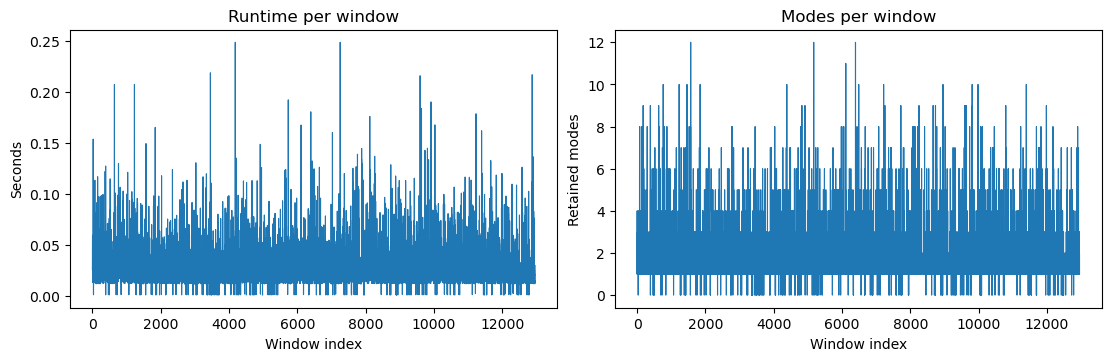

In [33]:
print(f"Analysis elapsed: {phase_timings['analysis_seconds'] / 60:.2f} min")
print(f"Windows: {len(window_timings):,}; retained modes: {len(mode_metrics):,}")
print(f"Fitted modes: {mode_metrics['metric_status'].eq('ok').sum():,}")
print("\nWindow outcomes:")
display(window_timings["status"].value_counts().rename_axis("status").to_frame("windows"))

timing_columns = ["enrichment_seconds", "islands_seconds", "line_metrics_seconds", "total_seconds"]
display(window_timings[timing_columns].agg(["sum", "mean", "median", "max"]).T)
display(window_timings.nlargest(10, "total_seconds")[["window_idx", "chrom", "start", "end", "status",
        "n_modes", "n_islands", "evaluated_lags", "total_seconds"]])
display(mode_metrics.head())

figure, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].plot(window_timings["window_idx"], window_timings["total_seconds"], linewidth=0.8)
axes[0].set(xlabel="Window index", ylabel="Seconds", title="Runtime per window")
axes[1].plot(window_timings["window_idx"], window_timings["n_modes"], linewidth=0.8)
axes[1].set(xlabel="Window index", ylabel="Retained modes", title="Modes per window")
figure.savefig(RUN_DIR / "runtime_summary.png", dpi=160)
plt.show()

## Inspect modes without an app

The two hover totals, `window_ip_plus_in_A` and `window_ip_plus_in_B`, sum all 300 positions across all IP and IN replicates for each condition. These are unnormalized **bigWig coverage sums**, not guaranteed unique-read counts. Different library sizes or replicate counts affect these totals. They describe the whole window and are repeated for every mode in it; they do not enter clustering.

The following cells can be run on an already-completed analysis without repeating the batch. They require the loaded `raw_arrays`, `window_metadata`, `mode_metrics`, and `RUN_DIR`. The updated totals are saved into `mode_metrics.tsv`. Rerunning the clustering section carries them into its saved table too.

With widget support, click a point in either scatter to display its window using the existing heatmap formatting. The clicked mode is highlighted; the copyable mode-key box also accepts a pasted key. The inspector loads saved enrichment signals and recalculates only that window using its recorded island parameters. Its mode membership and score are checked before plotting.

Heatmaps include the cyan quantile-matching curve, orange median-centered angle line and median marker, and a dotted white mode-box diagonal as the angle-offset reference. Quantile and angle lines are clipped to the mode mask, leaving gaps between islands. The original dashed white window diagonal remains separate. The run's saved quantile parameters and angle quantiles are used; undefined angle lines are omitted for degenerate modes. This does not change the batch metrics or clustering.

After updating `utils.py`, `mode_line_metrics.py`, and this notebook, rerun the utility-import cell and the inspection-helper cell. The helper reloads the line-metric module. No kernel restart or batch rerun is needed to add the overlays to existing results.

For current Plotly widget support, run `%pip install anywidget ipywidgets` in the notebook's kernel environment if needed, restart the kernel, and reload your results. These packages are optional: `show_window_heatmap(4543, mode_id=1)` or `show_mode_heatmap("the full hovered mode_key")` works without them. Click callbacks require a live widget-enabled notebook and kernel; exported HTML retains hover/rotation but does not call Python.

To inspect an earlier run after restarting: load its `mode_metrics.tsv` into `mode_metrics`, `window_metadata.tsv` into `window_metadata`, set `RUN_DIR`, import the matching utilities and plotting helpers, and run the inspection helpers below. Coverage totals additionally need the matching input archive loaded as `raw_arrays`; saved enrichment alone cannot recover raw IP/IN totals.

In [34]:
COUNT_COLUMNS = ["window_ip_A", "window_in_A", "window_ip_B", "window_in_B",
                 "window_ip_plus_in_A", "window_ip_plus_in_B"]

# Sum unnormalized coverage across positions and replicates.
window_counts = window_metadata[["comparison_key", "window_idx"]].copy()
indices = window_counts["window_idx"].to_numpy(dtype=int)
for side in ("A", "B"):
    for group in ("ip", "in"):
        window_counts[f"window_{group}_{side}"] = raw_arrays[f"{group}_{side}"].sum(axis=(1, 2), dtype=float)[indices]
    window_counts[f"window_ip_plus_in_{side}"] = window_counts[f"window_ip_{side}"] + window_counts[f"window_in_{side}"]

def add_window_counts(table):
    """Attach coverage totals by comparison and original window index."""
    keys = ["comparison_key", "window_idx"]
    lookup = window_counts.set_index(keys)
    requested = pd.MultiIndex.from_frame(table[keys])
    if not requested.isin(lookup.index).all():
        raise ValueError("The table contains windows outside the loaded comparison.")
    counts = lookup.reindex(requested)
    result = table.copy()
    for column in COUNT_COLUMNS:
        result[column] = counts[column].to_numpy()
    return result

mode_metrics = add_window_counts(mode_metrics)
write_tsv(mode_metrics, RUN_DIR / "mode_metrics.tsv")
display(mode_metrics[["mode_key", "window_ip_plus_in_A", "window_ip_plus_in_B"]].head())

,mode_key,window_ip_plus_in_A,window_ip_plus_in_B
0,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...,21267.0,17482.0
1,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...,15180.0,21127.0
2,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...,15180.0,21127.0
3,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...,15180.0,21127.0
4,PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w...,15180.0,21127.0


In [35]:
from functools import lru_cache
import importlib
import mode_line_metrics as inspection_metrics
inspection_metrics = importlib.reload(inspection_metrics)

CLICK_TO_INSPECT = True

@lru_cache(maxsize=1)
def inspection_signals(path, modified_ns):
    """Cache one run's saved enrichment signals."""
    with np.load(path, allow_pickle=False) as archive:
        indices = archive["window_idx"]
        signal_a, signal_b = archive["signal_A"], archive["signal_B"]
    if len(np.unique(indices)) != len(indices) or signal_a.shape != (len(indices), 300) or signal_b.shape != signal_a.shape:
        raise ValueError("Invalid saved signal archive.")
    return {int(index): row for row, index in enumerate(indices)}, signal_a, signal_b

def show_mode_heatmap(mode_key, all_modes=False, return_result=False):
    """Rebuild one window and highlight the requested mode."""
    matches = mode_metrics.loc[mode_metrics["mode_key"].eq(str(mode_key))]
    if len(matches) != 1:
        raise ValueError("Provide one exact mode_key from this run's mode table.")
    row = matches.iloc[0]
    index, mode_id = int(row["window_idx"]), int(row["mode_id"])
    archive_path = (RUN_DIR / "enrichment_signals.npz").resolve()
    positions, saved_a, saved_b = inspection_signals(str(archive_path), archive_path.stat().st_mtime_ns)
    if index not in positions:
        raise ValueError(f"No saved enrichment signals for window {index}.")
    signal_a, signal_b = saved_a[positions[index]], saved_b[positions[index]]
    if not np.isfinite(signal_a).all() or not np.isfinite(signal_b).all():
        raise ValueError(f"Window {index} was not completed in this run.")

    # Use the recorded parameters and saved signals, not current enrichment settings.
    manifest = json.loads((RUN_DIR / "run_manifest.json").read_text())
    if str(manifest["comparison_key"]) != str(row["comparison_key"]):
        raise ValueError("The selected mode table belongs to a different RUN_DIR.")
    result = analysis_utils.identify_islands(signal_a, signal_b, plot=False, **manifest["island_parameters"])
    selected = next((mode for mode in result["modes"] if mode["mode_id"] == mode_id), None)
    saved_members = tuple(sorted(int(value) for value in str(row["island_ids"]).split(",") if value))
    if selected is None or tuple(sorted(selected["islands"])) != saved_members:
        raise ValueError("The reconstructed mode differs from this run. Check the utils.py version.")
    if not np.isclose(selected["selection_score"], row["total_shape_adjusted_signal"], rtol=1e-6, atol=1e-8):
        raise ValueError("The reconstructed score differs from this run. Check the utils.py version.")

    plotted = dict(result)
    if not all_modes:
        plotted["modes"] = [selected]
    mode_lines = {
        mode["mode_id"]: inspection_metrics.quantile_plot_lines(
            result["matrix"], mode, manifest["quantile_parameters"], manifest["angle_quantiles"])
        for mode in inspection_metrics.surviving_mode_regions(plotted)
    }
    title = (f'{row["experiment_A"]} vs {row["experiment_B"]}\n'
             f'{row["chrom"]}:{row["start"]}-{row["end"]} ({row["strand"]}) | window {index}; mode {mode_id}')
    result["figure"], result["axes"] = analysis_utils.plot_islands(plotted, title=title, mode_lines=mode_lines)
    result["mode_lines"] = mode_lines
    result["inspected_mode_key"] = str(mode_key)
    plt.close(result["figure"])
    return result if return_result else None

def show_window_heatmap(window_idx, mode_id=None):
    """Inspect a window using the short numeric IDs from a hover label."""
    matches = mode_metrics.loc[mode_metrics["window_idx"].eq(window_idx)]
    if mode_id is not None:
        matches = matches.loc[matches["mode_id"].eq(mode_id)]
    if matches.empty:
        raise ValueError("No matching mode exists in this run's mode table.")
    return show_mode_heatmap(matches.iloc[0]["mode_key"], all_modes=mode_id is None)

def display_mode_scatter(figure):
    """Attach notebook click callbacks when widget support is available."""
    if not CLICK_TO_INSPECT:
        figure.show()
        return figure
    try:
        import ipywidgets as widgets
        from plotly.graph_objects import FigureWidget
        widget = FigureWidget(figure)
    except ImportError:
        print("Click inspection needs anywidget and ipywidgets. Use show_window_heatmap(window_idx, mode_id) for now.")
        figure.show()
        return figure

    selected_key = widgets.Text(description="Mode key:", layout=widgets.Layout(width="95%"))
    show_button = widgets.Button(description="Show heatmap")
    output = widgets.Output()

    def render_heatmap(key):
        selected_key.value = key
        with output:
            output.clear_output(wait=True)
            try:
                show_mode_heatmap(key)
            except Exception:
                traceback.print_exc()

    def on_click(trace, points, state):
        if points.point_inds:
            # Point indices belong to this trace, not the full clustered table.
            key = str(trace.customdata[points.point_inds[0]][0])
            render_heatmap(key)

    for trace in widget.data:
        trace.on_click(on_click)
    show_button.on_click(lambda button: render_heatmap(selected_key.value.strip()))
    display(widgets.VBox([widget, widgets.HBox([selected_key, show_button]), output]))
    return widget

# Manual alternatives; no widget packages are needed.
# show_window_heatmap(4543, mode_id=1)
# show_mode_heatmap(mode_metrics.iloc[0]["mode_key"])
# show_mode_heatmap(mode_metrics.iloc[0]["mode_key"], all_modes=True)

## Mode scatter

Each point is one mode. Hover labels include its mode key, window coordinates, allowed lag interval, and A/B window IP+IN coverage totals when Plotly is available. With widget support, click a point to inspect its heatmap below the plot. No sampling or grouping by window is applied.

Missing angle/displacement values from degenerate fits are excluded from this plot but remain in `mode_metrics.tsv`.

In [40]:
def valid_mode_rows(table):
    values = table[["angle_deg", "displacement_nt", "total_shape_adjusted_signal"]].to_numpy(dtype=float)
    return table["metric_status"].eq("ok") & np.isfinite(values).all(axis=1) & (values[:, 2] >= 0)


def plot_mode_scatter(table, name, clustered=False):
    if not {"window_ip_plus_in_A", "window_ip_plus_in_B"}.issubset(table.columns):
        table = add_window_counts(table)
    plotted = table.loc[valid_mode_rows(table)].copy()
    if plotted.empty:
        print("No finite mode metrics are available to plot.")
        return None
    plotted["log1p_signal"] = np.log1p(plotted["total_shape_adjusted_signal"])
    if clustered:
        plotted["cluster_label"] = plotted["cluster"].map(lambda label: "Noise" if label == -1 else f"Cluster {int(label)}")

    labels = dict(angle_deg="Angle offset (degrees)", displacement_nt="Box-relative displacement (nt)",
                  log1p_signal="log1p(shape-adjusted signal)", cluster_label="DBSCAN",
                  window_ip_plus_in_A="A IP+IN (coverage sum)", window_ip_plus_in_B="B IP+IN (coverage sum)")
    if px is not None:
        figure = px.scatter_3d(
            plotted, x="angle_deg", y="displacement_nt", z="log1p_signal",
            color="cluster_label" if clustered else None, opacity=0.7,
            color_discrete_map={"Noise": "#a0a0a0"}, labels=labels,
            custom_data=["mode_key"],
            hover_name="mode_key", hover_data=["window_idx", "window_ip_plus_in_A", "window_ip_plus_in_B"],
            title="Modes across one comparison" + (" — DBSCAN" if clustered else "")
        )
        figure.update_traces(marker_size=3)
        figure.update_layout(height=720)
        figure.write_html(RUN_DIR / f"{name}.html", include_plotlyjs=True)
        figure = display_mode_scatter(figure)
    else:
        figure = plt.figure(figsize=(10, 7))
        axis = figure.add_subplot(111, projection="3d")
        if clustered:
            for label, group in plotted.groupby("cluster"):
                axis.scatter(group["angle_deg"], group["displacement_nt"], group["log1p_signal"],
                             s=12, alpha=0.65, color="#a0a0a0" if label == -1 else None,
                             label="Noise" if label == -1 else f"Cluster {int(label)}")
            axis.legend()
        else:
            axis.scatter(plotted["angle_deg"], plotted["displacement_nt"], plotted["log1p_signal"], s=12, alpha=0.65)
        axis.set(xlabel=labels["angle_deg"], ylabel=labels["displacement_nt"], zlabel=labels["log1p_signal"])
        figure.savefig(RUN_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
        plt.show()
    return figure


scatter = plot_mode_scatter(mode_metrics, "mode_scatter")

    'data': [{'customdata': array([['PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661IC…

In [ ]:
Keys to fix: 

PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ:w0011927:m1

## Exploratory clustering

DBSCAN can leave isolated points as noise and does not require choosing a cluster count. It is applied to the same three metrics, after `log1p` transformation of the signal score and standardization of each feature.

`eps` is a neighborhood radius in standardized feature space; `min_samples` counts the point itself. These settings are exploratory. A single cluster or all-noise result is valid; clusters are not evidence of distinct biological classes. Modes from overlapping windows can repeat similar signal, and points are not independent observations.

The sorted neighbor-distance plot helps tune `DBSCAN_EPS`. Rerun this section to try other settings without rerunning island identification.

Clusters: 1; noise modes: 268/19,417


,n_modes,n_windows,median_angle_deg,median_displacement_nt,median_signal
cluster,,,,,
-1,268,264,-5.328752,4.281160,69.694704
0,19149,12536,-0.459675,-0.028122,279.526588


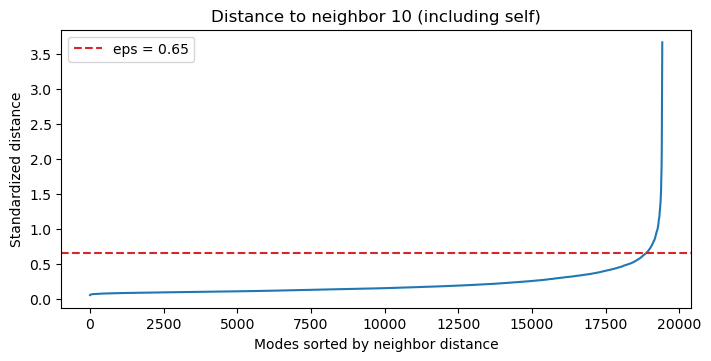

Clustering elapsed: 1.47 s


In [37]:
started = perf_counter()
clustered_modes = mode_metrics.copy()
clustered_modes["cluster"] = pd.Series(pd.NA, index=clustered_modes.index, dtype="Int64")
valid = valid_mode_rows(clustered_modes)
fitted_indices = clustered_modes.index[valid]

if len(fitted_indices):
    features = clustered_modes.loc[valid, ["angle_deg", "displacement_nt", "total_shape_adjusted_signal"]].to_numpy(dtype=float, copy=True)
    features[:, 2] = np.log1p(features[:, 2])
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(features)
    cluster_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES, n_jobs=1).fit_predict(scaled_features)
    clustered_modes.loc[fitted_indices, "cluster"] = cluster_labels

    scaling = pd.DataFrame({"feature": ["angle_deg", "displacement_nt", "log1p_signal"],
                            "mean": scaler.mean_, "scale": scaler.scale_})
    write_tsv(scaling, RUN_DIR / "clustering_scaling.tsv")

    n_clusters = len(set(cluster_labels) - {-1})
    print(f"Clusters: {n_clusters}; noise modes: {(cluster_labels == -1).sum():,}/{len(cluster_labels):,}")
    display(clustered_modes.loc[valid].groupby("cluster").agg(
        n_modes=("mode_id", "size"), n_windows=("window_idx", "nunique"),
        median_angle_deg=("angle_deg", "median"), median_displacement_nt=("displacement_nt", "median"),
        median_signal=("total_shape_adjusted_signal", "median")
    ))

    if len(fitted_indices) >= DBSCAN_MIN_SAMPLES:
        neighbors = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(scaled_features)
        distances, _ = neighbors.kneighbors(scaled_features)
        figure, axis = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
        axis.plot(np.sort(distances[:, -1]))
        axis.axhline(DBSCAN_EPS, color="C3", linestyle="--", label=f"eps = {DBSCAN_EPS}")
        axis.set(xlabel="Modes sorted by neighbor distance", ylabel="Standardized distance",
                 title=f"Distance to neighbor {DBSCAN_MIN_SAMPLES} (including self)")
        axis.legend()
        figure.savefig(RUN_DIR / "dbscan_neighbor_distances.png", dpi=160)
        plt.show()
    else:
        print("Fewer modes than min_samples: DBSCAN labels all fitted modes as noise.")
else:
    print("No fitted modes are available for clustering.")

phase_timings["clustering_seconds"] = perf_counter() - started
write_tsv(clustered_modes, RUN_DIR / "mode_metrics_clustered.tsv")
write_manifest(RUN_DIR, dict(completed=True, processed_windows=len(window_timings), retained_modes=len(mode_metrics)))
print(f"Clustering elapsed: {phase_timings['clustering_seconds']:.2f} s")

In [38]:
clustered_scatter = plot_mode_scatter(clustered_modes, "mode_scatter_clustered", clustered=True)

    'data': [{'customdata': array([['PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661IC…

## Saved results

Each run creates:

- `mode_metrics.tsv`: one row per retained mode, including degenerate line fits.
- `mode_metrics_clustered.tsv`: the same rows plus DBSCAN labels; `-1` means noise and an empty label means an unfitted mode.
- `window_timings.tsv`: one row per processed window, including zero-mode and failed windows.
- `window_metadata.tsv`: coordinates and stable identifiers for every input window.
- `enrichment_signals.npz`: averaged A/B signals indexed by the original `window_idx`; windows without calculated signals are NaN after an interrupted run.
- `run_manifest.json`: parameters, source path and hash, package versions, input identity, completion status, and stage timings.
- Scatter HTML files (or PNG fallbacks), runtime plots, and a neighbor-distance plot when there are enough modes.
- `errors.log` if an unexpected window error occurred.

The scatter's mode key maps directly to the saved table and its window index. A future inspector can rerun `analysis_utils.identify_islands(signal_A[index], signal_B[index], plot=False, **ISLAND_PARAMETERS)` and use the existing heatmap formatting, without retaining every matrix in memory.

Checkpoints preserve partial results; automatic resume is not implemented. Re-executing the batch cell starts a fresh run.

In [39]:
print(f"Results: {RUN_DIR.resolve()}")
display(pd.DataFrame([{"stage": stage, "seconds": seconds} for stage, seconds in phase_timings.items()]))

Results: /tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_correspondance/mode_analysis_results/PUM1_K562_ENCSR308YNT__PUM2_K562_ENCSR661ICQ_20261028_110757_467013


,stage,seconds
0,candidate_scan_seconds,0.470252
1,load_seconds,0.212712
2,analysis_seconds,115.214571
3,clustering_seconds,1.472797
